In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

In [3]:
def hessian_r2(C,w,g): #这里的w 和 g是△w he △g
    n = w.size
    d = g.dot(w)
    if math.fabs(d) < 1e-4:
        return np.identity(n)
    A = np.zeros((n,n))
    for i  in range(n):
        A[i] = g[i] *g
    A /=d
    B = np.zeros((n,n))
    w2 = C.dot(w)
    for i in range(n):
        B[i] = w2[i] * w2
    d2 = w.dot(w2)
    if math.fabs(d2) < 1e-4:
        return np.identity(n)
    B /= d2
    return C+A-B
    
    

In [6]:
def hessian_r(C,w,g): #这里的w 和 g是△w he △g
    n = w.size
    d = g.dot(w)
    if math.fabs(d) < 1e-5:
        return np.identity(n)
    A = np.zeros((n,n))
    B = np.zeros((n,n))
    for i  in range(n):
        A[i] = w[i] *g
        B[i] = w[i] *w
    A /=d
    At = A.transpose()
    B /= d
    I = np.identity(n)
    return (I - A).dot(C).dot(I - At) + B
    

In [7]:
np.identity(10)
a = np.array([1,2,3,4]).reshape(2,2)
np.linalg.inv(a)

array([[-2. ,  1. ],
       [ 1.5, -0.5]])

In [ ]:
def lr_BFGS(data,alpha):
    n = len(data[0]) -1
    w0 = np.zeros(n)
    w = np.zeros(n)
    g0 = np.zeros(n)
    g = np.zeros(n)
    C = np.identity(n)
    for times in range(1000):
        for d in data:
            x = np.array(d[:-1])
            y = d[-1]
            C = hessian_r(C,w-w0,g-g0)
            g0 = g
            w0 = w
            g = (y - pred(w,x)) * x
            w = w + alpha * C.dot(g)
        print(times,w)
    return w

1.0

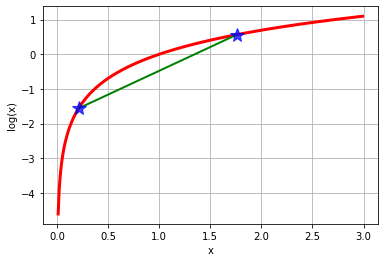

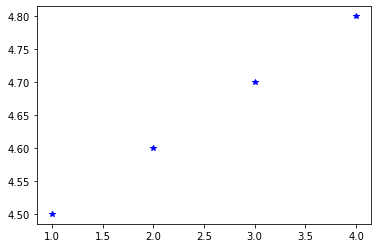

In [17]:
plt.plot([1,2,3,4],[4.5,4.6,4.7,4.8],'b*')